# Injection-recovery in the 10-year RV residuals: $T_s$ = 300, 400, 500 K and HARPS-N

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt

from sunsim.residuals import ResidualAnalysis

plt.rcParams.update({"font.size": 13, "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True,
                     "ytick.right": True})

RESULTS = 'results/10_years_injection'
PERIOD_TOL = 0.1
ROTATION = 26
T_SPOT = {2: 300, 3: 400, 4: 500}        # rv-X: T_s [K]
LABEL = {x: '$T_s$ = %d K' % T for x, T in T_SPOT.items()}
COLOURS = {LABEL[2]: '#2a9d8f', LABEL[3]: '#e76f51', LABEL[4]: '#ea8642', 'HARPS-N': '#102e37'}

series = {LABEL[x]: ResidualAnalysis.load(os.path.join(RESULTS, 'residuals_rv-%s.npz' % x)) for x in T_SPOT}
series['HARPS-N'] = ResidualAnalysis.load(os.path.join(RESULTS, 'harpsn.npz'))
inj = series['HARPS-N'].injection
print('periods', inj['periods'], '\namplitudes', inj['amplitudes'][[0, -1]], len(inj['amplitudes']),
      '\nphases', inj['fap'].shape[2], ' FAP <=', inj['fap_fit'])

periods [  5.  60. 115. 170. 225. 280. 335. 390. 445. 500.] 
amplitudes [0.1 0.5] 21 
phases 100  FAP <= 0.001


## Periodograms

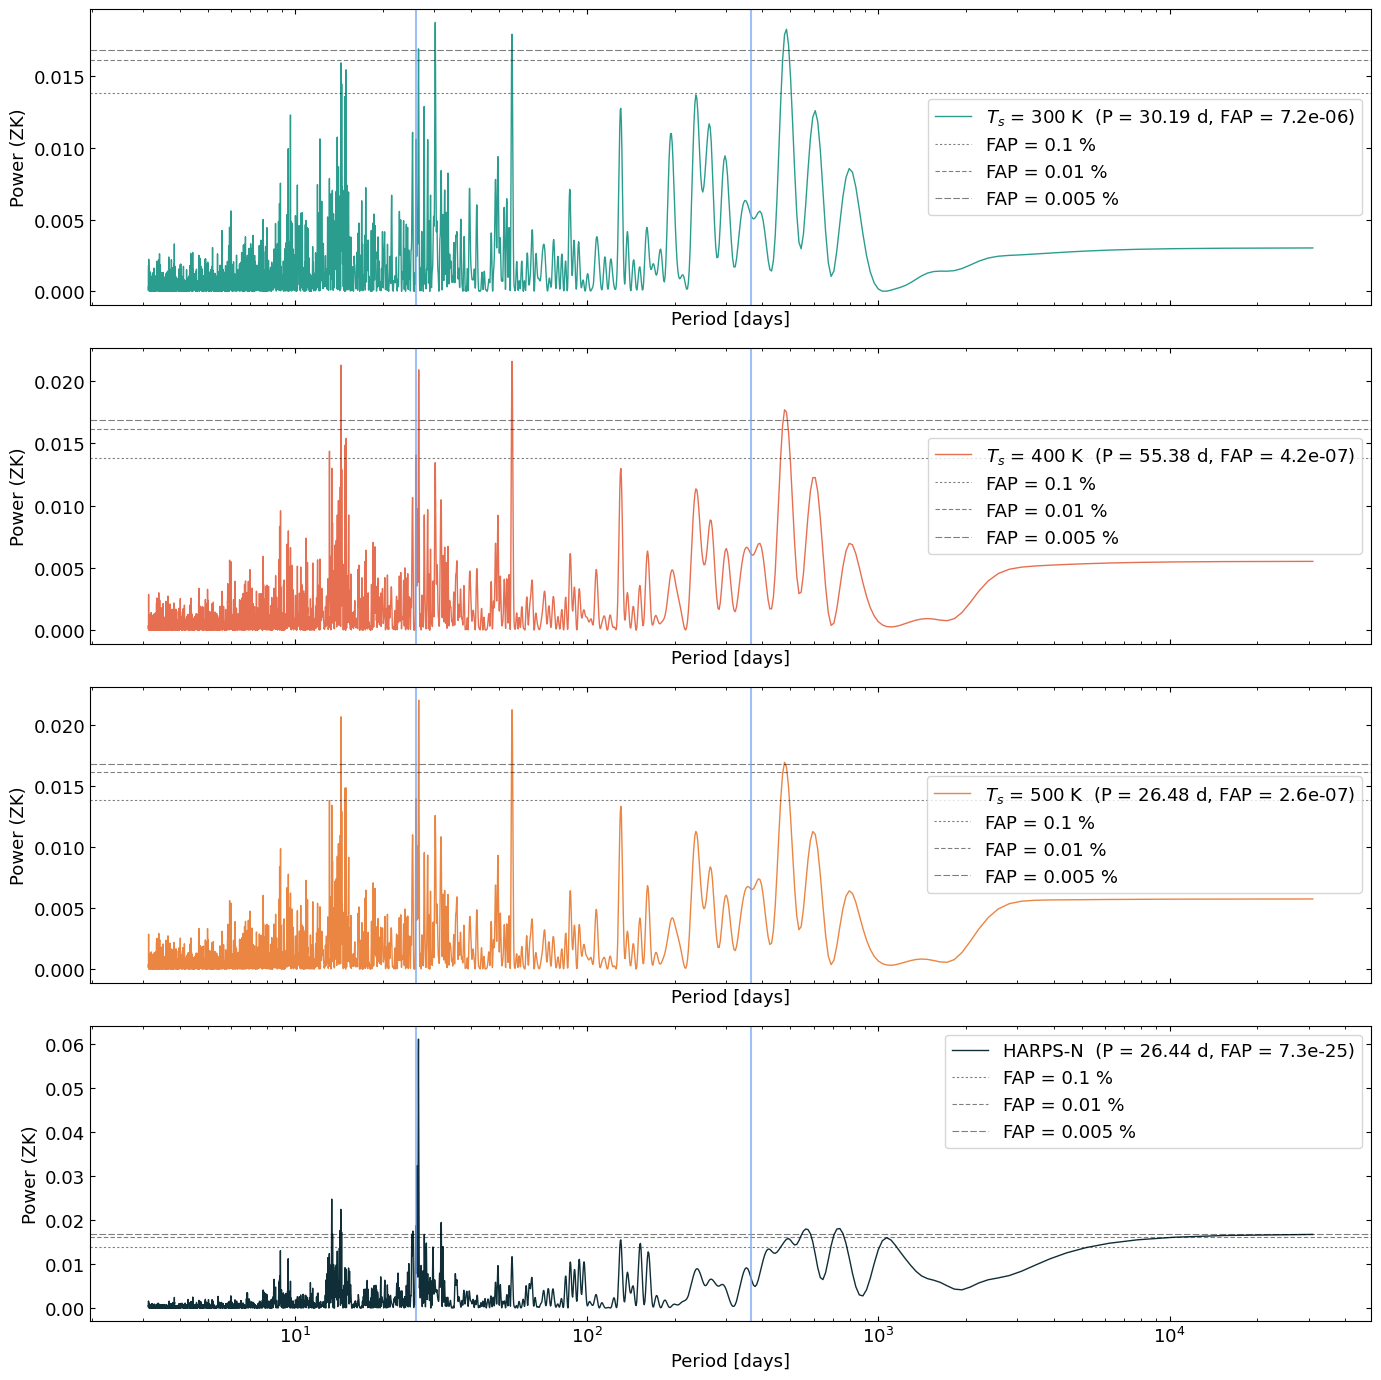

In [2]:
fig, axes = plt.subplots(len(series), 1, figsize=(14, 3.5 * len(series)), sharex=True)
for ax, (name, ra) in zip(axes, series.items()):
    ra.plot_periodogram(ax, mark=(ROTATION, 365), color=COLOURS[name], label=name)
fig.tight_layout()
plt.show()

## Detection maps

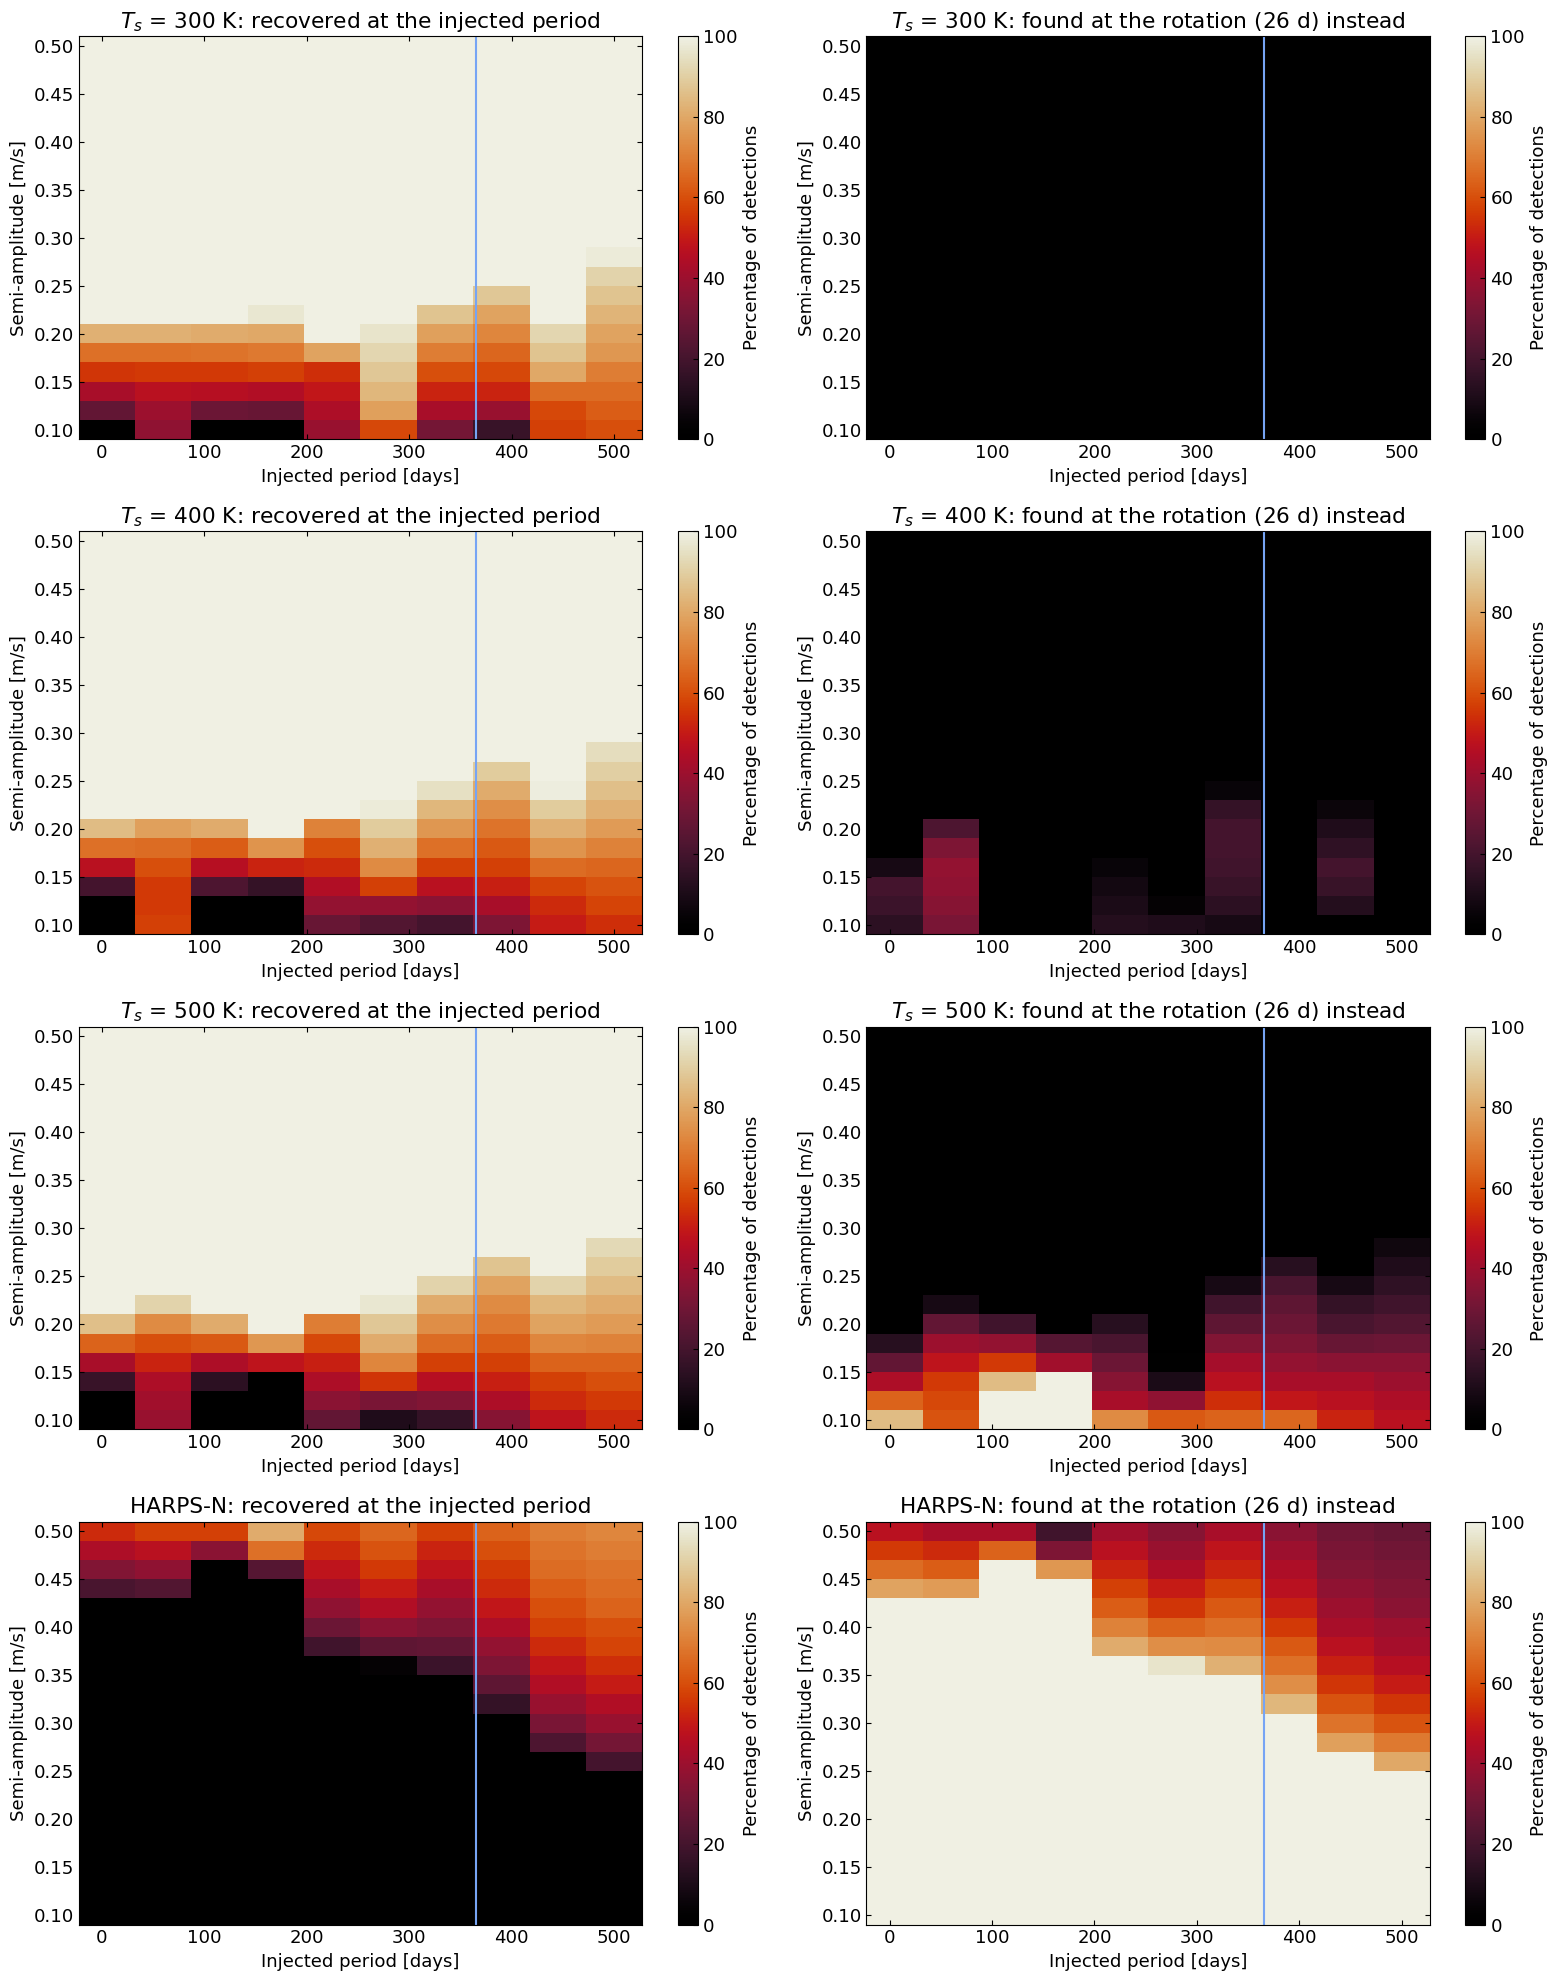

In [3]:
kinds = {'recovered at the injected period': dict(period_tol=PERIOD_TOL),
         'found at the rotation (%g d) instead' % ROTATION: dict(period_tol=PERIOD_TOL, at_period=ROTATION)}
fig, axes = plt.subplots(len(series), len(kinds), figsize=(8 * len(kinds), 5 * len(series)), squeeze=False)
for row, (name, ra) in zip(axes, series.items()):
    for ax, (title, kw) in zip(row, kinds.items()):
        ra.plot_detection_map(ra.detection_rate(**kw), ax, title='%s: %s' % (name, title))
fig.tight_layout()
plt.show()

## Detection limits

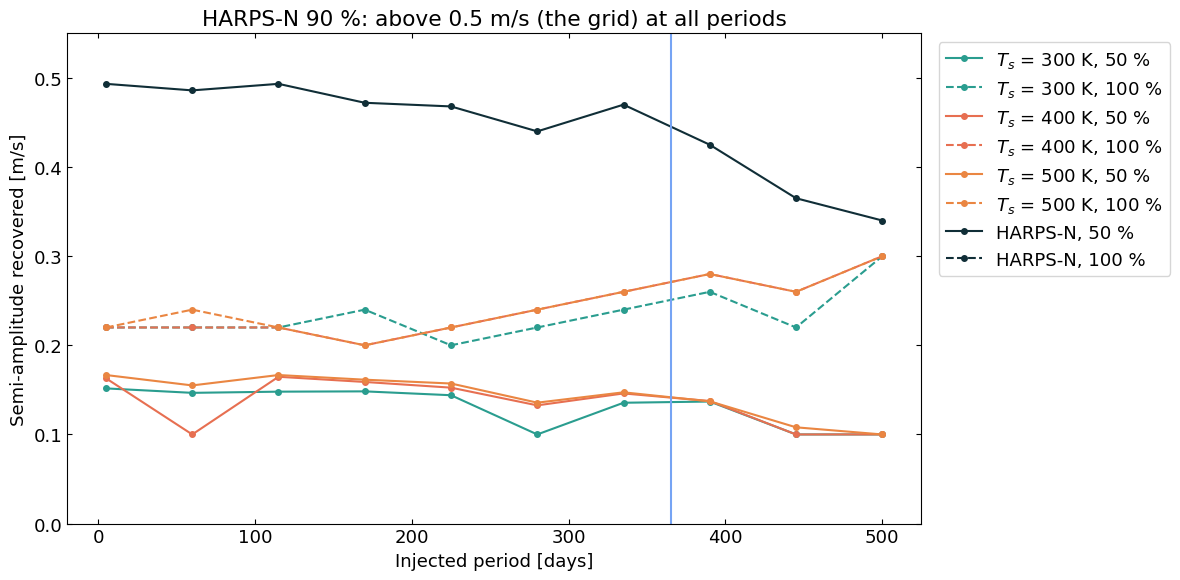

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))
for name, ra in series.items():
    for level, ls in ((50, '-'), (100, '--')):
        ax.plot(inj['periods'], ra.detection_limit(level, period_tol=PERIOD_TOL), ls, marker='o', ms=4,
                color=COLOURS[name], label='%s, %d %%' % (name, level))
ax.axvline(365, color='#76a4f4')
ax.set_title('HARPS-N 90 %%: above %.1f m/s (the grid) at all periods' % inj['amplitudes'].max()
             if np.all(np.isnan(series['HARPS-N'].detection_limit(90, period_tol=PERIOD_TOL))) else '')
ax.set_xlabel('Injected period [days]')
ax.set_ylabel('Semi-amplitude recovered [m/s]')
ax.set_ylim(0, 0.55)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()

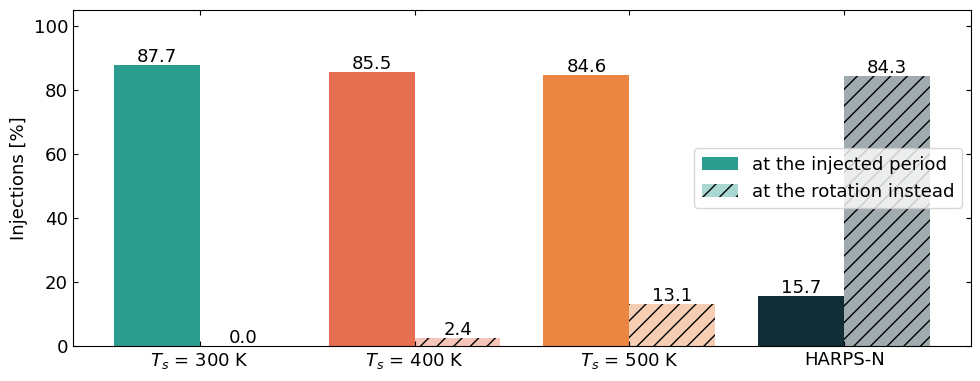

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(series))
rec = [ra.detection_rate(period_tol=PERIOD_TOL).mean() for ra in series.values()]
rot = [ra.detection_rate(period_tol=PERIOD_TOL, at_period=ROTATION).mean() for ra in series.values()]
ax.bar(x - 0.2, rec, 0.4, color=[COLOURS[n] for n in series], label='at the injected period')
ax.bar(x + 0.2, rot, 0.4, color=[COLOURS[n] for n in series], alpha=0.4, hatch='//', label='at the rotation instead')
for i, (a, b) in enumerate(zip(rec, rot)):
    ax.text(i - 0.2, a + 1, '%.1f' % a, ha='center')
    ax.text(i + 0.2, b + 1, '%.1f' % b, ha='center')
ax.set_xticks(x, list(series))
ax.set_ylabel('Injections [%]')
ax.set_ylim(0, 105)
ax.legend()
fig.tight_layout()
plt.show()

## Residuals - HARPS-N

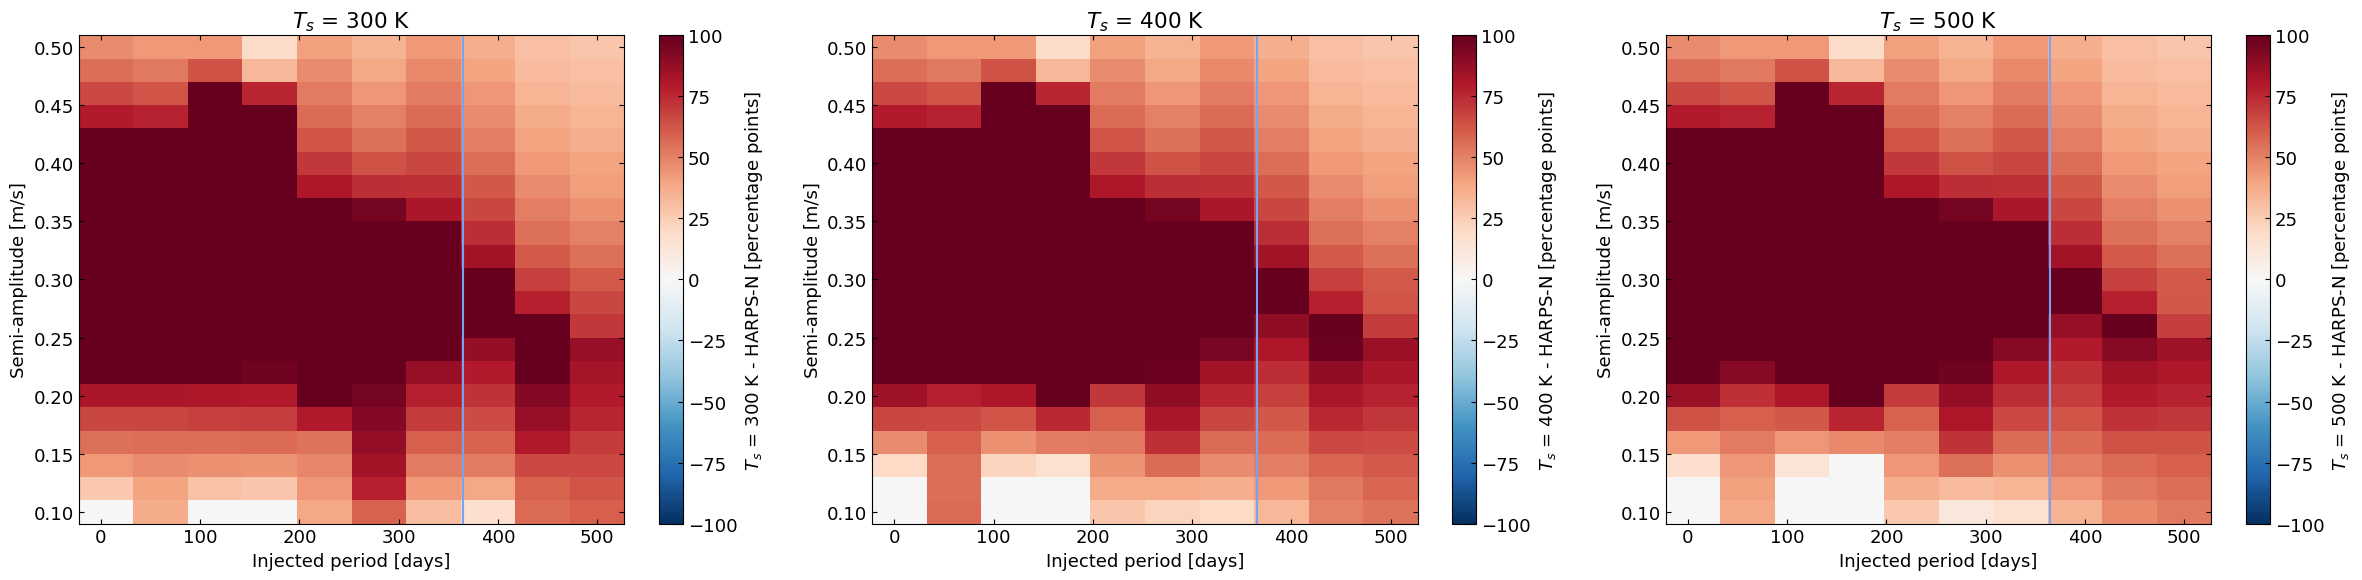

In [6]:
ref = series['HARPS-N']
rate_ref = ref.detection_rate(period_tol=PERIOD_TOL)
names = [n for n in series if n != 'HARPS-N']
fig, axes = plt.subplots(1, len(names), figsize=(8 * len(names), 6))
for ax, name in zip(axes, names):
    diff = series[name].detection_rate(period_tol=PERIOD_TOL) - rate_ref
    series[name].plot_detection_map(diff, ax, cmap='RdBu_r', vmin=-100, vmax=100,
                                    label='%s - HARPS-N [percentage points]' % name, title=name)
fig.tight_layout()
plt.show()

## Recovered semi-amplitudes and periods

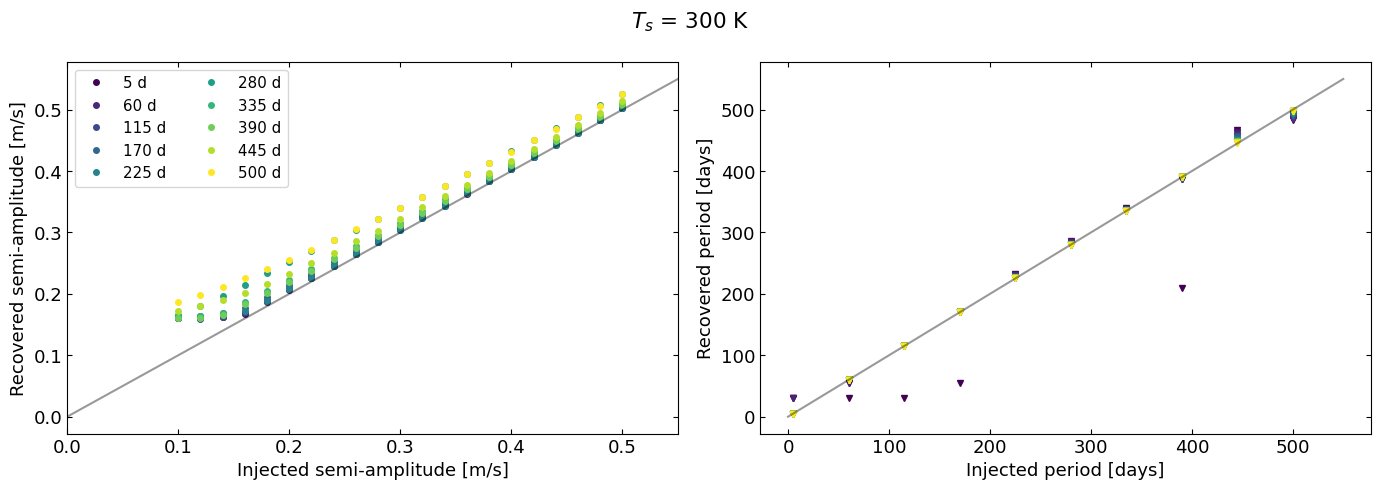

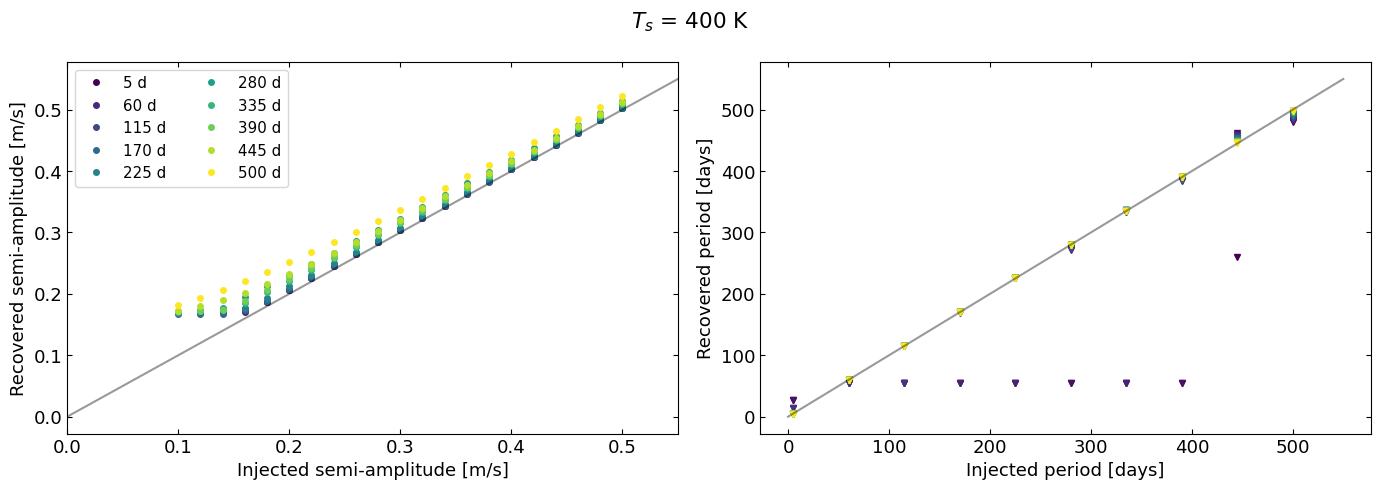

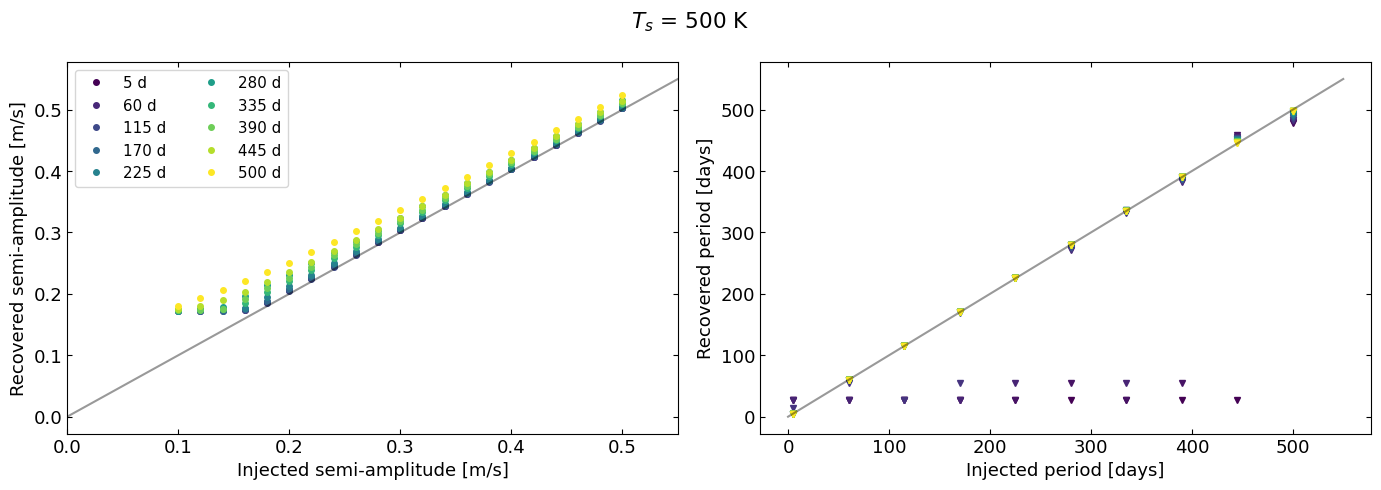

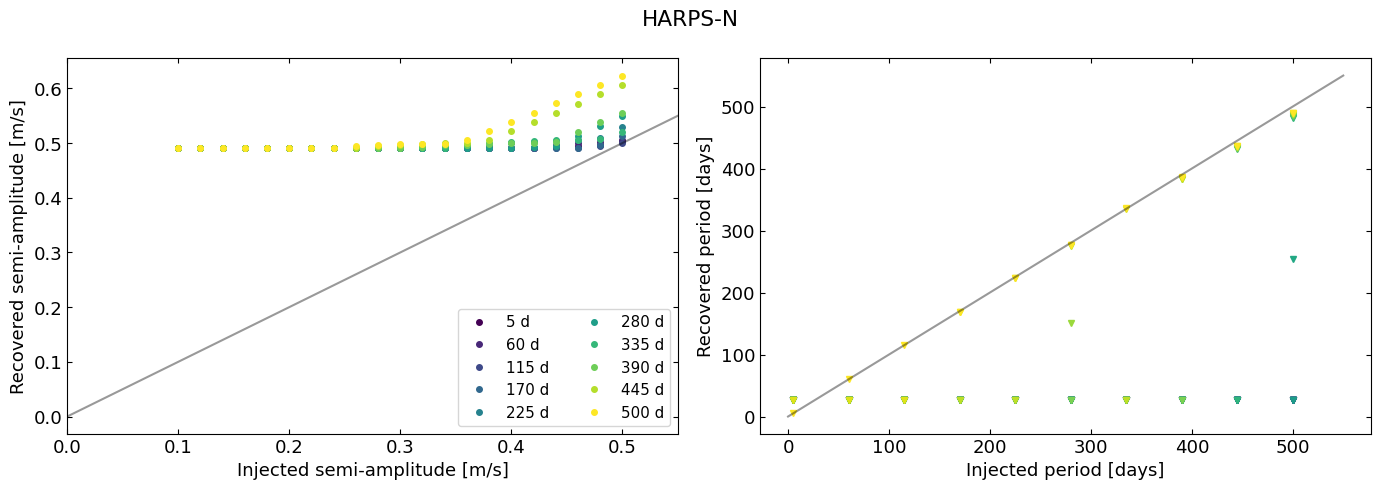

In [7]:
for name, ra in series.items():
    axes = ra.plot_recovered()
    axes[0].figure.suptitle(name)
    axes[0].figure.tight_layout()
    plt.show()